Epoch 1/20, Loss: 0.9769332077503204
Epoch 2/20, Loss: 0.9498110665678978
Epoch 3/20, Loss: 0.936068968653679
Epoch 4/20, Loss: 0.9275178614258767
Epoch 5/20, Loss: 0.9215836952328682
Epoch 6/20, Loss: 0.9171839657425881
Epoch 7/20, Loss: 0.9137710046768188
Epoch 8/20, Loss: 0.9110442957282067
Epoch 9/20, Loss: 0.9088167726993561
Epoch 10/20, Loss: 0.9069643502831459
Epoch 11/20, Loss: 0.9054052955508232
Epoch 12/20, Loss: 0.9040782381892204
Epoch 13/20, Loss: 0.9029399736523628
Epoch 14/20, Loss: 0.901957014977932
Epoch 15/20, Loss: 0.9011032971739769
Epoch 16/20, Loss: 0.9003584219813346
Epoch 17/20, Loss: 0.8997060278058052
Epoch 18/20, Loss: 0.8991328237056733
Epoch 19/20, Loss: 0.898627524793148
Epoch 20/20, Loss: 0.8981810814738274


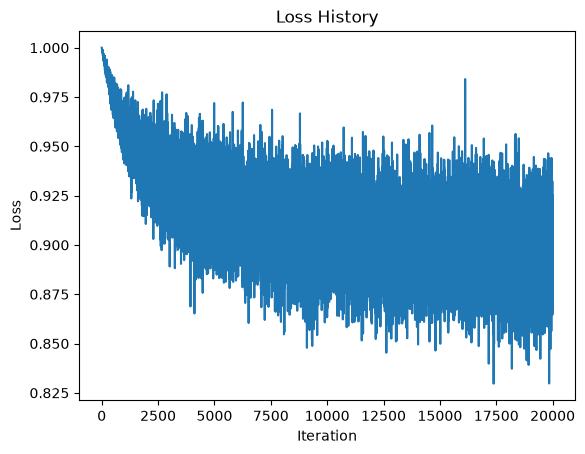

Training accuracy: 32.22%
Test accuracy: 32.42%


In [2]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

# 1. Dataloading
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]
)
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = (
    "plane",
    "car",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10  # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w = (torch.randn(Din, K) * std)  # One layer: directly map input to output
b = torch.zeros(K)

# Hyperparameters
iterations = 20
lr = 2e-6  # Learning rate
lr_decay = 0.9  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = (nn.functional.one_hot(labels, K).float())  # Convert labels to one-hot

        # Forward pass
        y_pred = x_train.mm(w) + b  # Output layer activation

        # Loss calculation (Mean Squared Error with regularization)
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) + reg * torch.sum(w ** 2)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Epoch 1/10, Loss: 2.0711891919374468
Epoch 2/10, Loss: 1.819261487364769
Epoch 3/10, Loss: 1.7291698914766311
Epoch 4/10, Loss: 1.6786141978502274
Epoch 5/10, Loss: 1.641053901195526
Epoch 6/10, Loss: 1.6091494407653808
Epoch 7/10, Loss: 1.58250422167778
Epoch 8/10, Loss: 1.5585657439231873
Epoch 9/10, Loss: 1.5366098914146424
Epoch 10/10, Loss: 1.5181932312250137


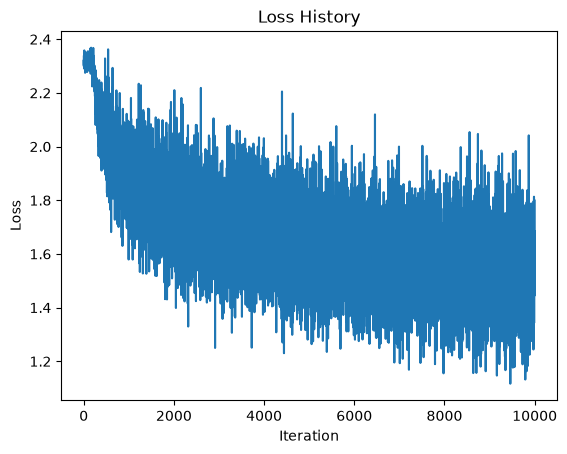

Training accuracy: 48.11%
Test accuracy: 45.82%


In [12]:
# Modified fully connected network with 100 unit hidden layer

# Define the sigmoid activation function
def sigmoid(x):
    return torch.sigmoid(x)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100  # Hidden layer size
K = 10  # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize modified weights and biases
w1 = (torch.randn(Din, H) * std)  # first layer weights ( Din - H)
b1 = torch.zeros(H)
w2 = (torch.randn(H, K) * std)  # second layer weights
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 8e-2  # Learning rate
lr_decay = 0.9  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = (nn.functional.one_hot(labels, K).float())  # Convert labels to one-hot

        # Forward pass
        # Modified using the new hidden layer
        a_1 = x_train.mm(w1) + b1  # First layer activation
        a_1 = sigmoid(a_1)  # Apply sigmoid activation
        y_pred = a_1.mm(w2) + b2  # Output layer activation

        # Loss calculation (Cross entrophy loss) calculated using PyTorch's built-in CrossEntropyLoss function.
        loss = nn.CrossEntropyLoss()(y_pred, labels) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        # Modified Backpropagation for the two-layer network
        y_pred_probs = torch.softmax(y_pred, dim=1)
        dy_pred =  (y_pred_probs - y_train_onehot) / Ntr

        dw2 = a_1.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        # Backpropagate to the hidden layer
        da_1 = dy_pred.mm(w2.t())
        dz_1 = da_1 * (a_1 * (1 - a_1))  # Derivative of sigmoid

        # Compute gradients for the first layer
        dw1 = x_train.t().mm(dz_1) + reg * w1
        db1 = dz_1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        a_1 = x_train.mm(w1) + b1
        a_1 = sigmoid(a_1)
        y_train_pred = a_1.mm(w2) + b2
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        a_1 = x_test.mm(w1) + b1
        a_1 = sigmoid(a_1)
        y_test_pred = a_1.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Training LeNet-5 on MNIST dataset for 10 epochs with lr=0.001, lr_decay=0.9, reg=0.0001
Epoch 1/10 | Train Loss: 0.0965 | Train Accuracy: 97.03% | Test Loss: 0.1025 | Test Accuracy: 96.84%
Epoch 2/10 | Train Loss: 0.0542 | Train Accuracy: 98.31% | Test Loss: 0.0677 | Test Accuracy: 97.84%
Epoch 3/10 | Train Loss: 0.0443 | Train Accuracy: 98.61% | Test Loss: 0.0584 | Test Accuracy: 98.11%
Epoch 4/10 | Train Loss: 0.0303 | Train Accuracy: 99.06% | Test Loss: 0.0474 | Test Accuracy: 98.54%
Epoch 5/10 | Train Loss: 0.0257 | Train Accuracy: 99.23% | Test Loss: 0.0457 | Test Accuracy: 98.59%
Epoch 6/10 | Train Loss: 0.0207 | Train Accuracy: 99.37% | Test Loss: 0.0459 | Test Accuracy: 98.44%
Epoch 7/10 | Train Loss: 0.0177 | Train Accuracy: 99.46% | Test Loss: 0.0433 | Test Accuracy: 98.65%
Epoch 8/10 | Train Loss: 0.0246 | Train Accuracy: 99.19% | Test Loss: 0.0524 | Test Accuracy: 98.33%
Epoch 9/10 | Train Loss: 0.0101 | Train Accuracy: 99.71% | Test Loss: 0.0383 | Test Accuracy: 98.77%
Epo

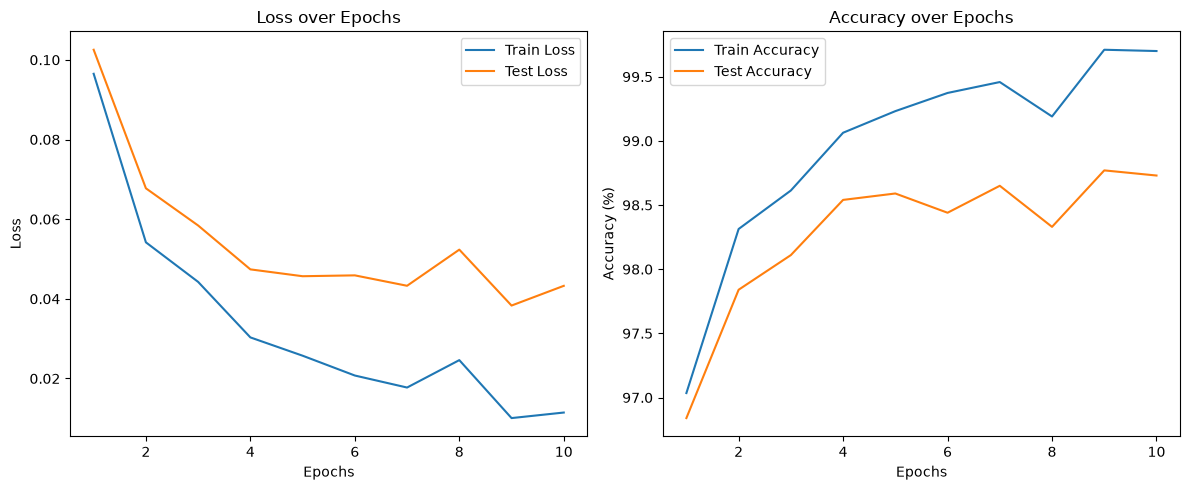

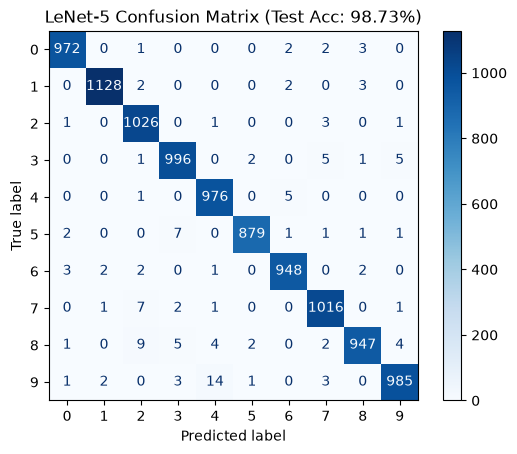

In [4]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Creating LeNet 5 using pytorch


def lenet_tanh(x):
    return 1.7159 * torch.tanh((2.0 / 3.0) * x)

# LeNet 5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)  # Input channels: 1 (grayscale), Output channels: 6 out_size = 28 x 28 x 6
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)  # Average pooling layer out_size = 14 x 14 x 6
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)  # Input channels: 6, Output channels: 16 out_size = 10 x 10 x 16
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)  # Second average pooling layer out_size = 5 x 5 x 16
        self.fc1 = nn.Linear(400, 120)  # Fully connected layer
        self.fc2 = nn.Linear(120, 84)  # Fully connected layer
        self.fc3 = nn.Linear(84, 10)  # Output layer for 10 classes

    def forward(self, x):
        x = lenet_tanh(self.conv1(x))  # Apply tanh activation after first convolution
        x = self.pool1(x)  # Apply average pooling
        x = lenet_tanh(self.conv2(x))  # Apply tanh activation after second convolution
        x = self.pool2(x)  # Apply average pooling
        x = torch.flatten(x, 1)  # Flatten the tensor for fully connected layers
        x = lenet_tanh(self.fc1(x))  # Apply tanh activation after first fully connected layer
        x = lenet_tanh(self.fc2(x))  # Apply tanh activation after second fully connected layer
        x = self.fc3(x)  # Output layer (no activation here as we'll use CrossEntropyLoss)
        return x


# Trainig the Models
def train(model, epochs, lr, lr_decay, reg):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)  # Move the model to the appropriate device (GPU or CPU)

    optimizer = optim.Adam(model.parameters(), lr=lr)
    loss_criterian = nn.CrossEntropyLoss()
    
    train_losses = []
    test_losses = []
    train_accuracies = []
    test_accuracies = []

    for epoch in range(epochs):
        model.train()  # Set the model to training mode

        for i, data in enumerate(trainloader_MNIST, 0):
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(inputs)
            
            l2 = sum((p ** 2).sum() for p in model.parameters() if p.dim() > 1)
            loss = loss_criterian(outputs, labels) + reg * l2

            # Backpropagation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Learning rate decay
        for param_group in optimizer.param_groups:
            param_group['lr'] *= lr_decay

        epoch_train_loss, epoch_train_accuracy = evaluate_model(model, trainloader_MNIST, loss_criterian, device)
        epoch_test_loss, epoch_test_accuracy = evaluate_model(model, testloader_MNIST, loss_criterian, device)

        train_losses.append(epoch_train_loss)
        test_losses.append(epoch_test_loss)
        train_accuracies.append(epoch_train_accuracy)
        test_accuracies.append(epoch_test_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Train Accuracy: {epoch_train_accuracy:.2f}% | "
            f"Test Loss: {epoch_test_loss:.4f} | "
            f"Test Accuracy: {epoch_test_accuracy:.2f}%")

    return model, train_losses, test_losses, train_accuracies, test_accuracies

def evaluate_model(model, dataloader,  loss_criterian, device, return_preds_labels=False):

    # validation Step after each epoch
    model.eval()  # Set the model to evaluation mode
    correct = 0
    loss = 0.0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for data in dataloader:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss += loss_criterian(outputs, labels).item() * inputs.size(0)

            predicted = torch.argmax(outputs, dim=1)
            correct += (predicted == labels).sum().item()
            if return_preds_labels:
                all_preds.append(predicted.cpu())
                all_labels.append(labels.cpu())

        loss = loss / len(dataloader.dataset)
        accuracy = 100 * correct / len(dataloader.dataset)

    if return_preds_labels:
        return loss, accuracy, torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()
    return loss, accuracy

def plot_graphs(tr_loss,tr_acc, te_loss, te_acc):

    epochs = range(1, len(tr_loss) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, tr_loss, label='Train Loss')
    plt.plot(epochs, te_loss, label='Test Loss')
    plt.title('Loss over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, tr_acc, label='Train Accuracy')
    plt.plot(epochs, te_acc, label='Test Accuracy')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":

    
    epochs = 10
    lr = 0.001
    lr_decay = 0.9
    reg = 0.0001
    batch_size = 50

    criterion = nn.CrossEntropyLoss()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    transform_MNIST = transforms.Compose([
        transforms.Pad(2),  # 28x28 -> 32x32
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,)) # Mnist dataset mean and std for normalization
        ])

    trainset_MNIST = torchvision.datasets.MNIST(root="./data_MNIST", train=True, download=True, transform=transform_MNIST)
    trainloader_MNIST = torch.utils.data.DataLoader(trainset_MNIST, batch_size=batch_size, shuffle=True, num_workers=2)
    testset_MNIST = torchvision.datasets.MNIST(root="./data_MNIST", train=False, download=True, transform=transform_MNIST)
    testloader_MNIST = torch.utils.data.DataLoader(testset_MNIST, batch_size=batch_size, shuffle=False, num_workers=2)

    model = LeNet5()

    print(f"Training LeNet-5 on MNIST dataset for {epochs} epochs with lr={lr}, lr_decay={lr_decay}, reg={reg}")
    trained_model, train_losses, test_losses, train_accuracies, test_accuracies = train(model, epochs, lr, lr_decay, reg)
    print(f"Final: Train Acc = {train_accuracies[-1]:.2f}% | Test Acc = {test_accuracies[-1]:.2f}%")
    plot_graphs(train_losses, train_accuracies, test_losses, test_accuracies)


    loss, acc, preds, labels = evaluate_model(trained_model, testloader_MNIST, criterion, device, return_preds_labels=True)
    cm = confusion_matrix(labels, preds)
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(cmap="Blues", values_format="d")
    plt.title(f"LeNet-5 Confusion Matrix (Test Acc: {acc:.2f}%)")
    plt.show()
